# Agentní modely

```{index} single: Model ; agentní
```

```{index} Individual-based model
```

```{admonition} Co se dozvíte v tomto textu

![](pics/agenti.png)

Dosud jsme populaci popisovali jedním číslem (případně několika čísly), které
vyjadřovalo velikost nebo hustotu populace, a vývoj tohoto čísla jsme popsali
diferenciální nebo diferenční rovnicí. V této kapitole půjdeme opačnou cestou.
Budeme sledovat jednotlivé jedince, takzvané agenty, a jejich chování popíšeme
jednoduchými pravidly, ve kterých hraje důležitou roli náhoda. Chování celé
populace potom nebude dáno rovnicí, ale vynoří se ze vzájemného působení mnoha
jedinců.

Uvidíme, že pro velké populace se agentní modely chovají podobně jako modely
založené na diferenciálních rovnicích. Agentní modely však navíc umožní sledovat
jevy, které deterministické rovnice nepostihnou: náhodné vymření malé populace,
kolísání velikosti populace kolem nosné kapacity nebo vznik prostorových struktur.

*Obrázek: Snímek simulace prostorového modelu dravce a kořisti z této kapitoly.
Modré body jsou jedinci kořisti, červené body jsou dravci.*
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from collections import defaultdict
import time

In [2]:
# Knihovna Mesa pro agentní modely. V Google Colab není předinstalovaná,
# proto ji v případě potřeby doinstalujeme.
import importlib.util
if importlib.util.find_spec("mesa") is None:
    %pip install -q mesa
import mesa
from mesa.discrete_space import OrthogonalMooreGrid, CellAgent

/mnt/python/miniforge3/envs/dmp/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Princip agentního modelu

Agentní modely (anglicky *agent-based models*, v ekologii častěji
*individual-based models*) jsou počítačové simulace, ve kterých sledujeme
každého jedince zvlášť. Každý jedinec má svůj stav (například polohu, věk,
zásobu energie nebo pohlaví) a v každém časovém kroku se podle předem daných
pravidel rozhoduje, co udělá. Může se přemístit, rozmnožit, ulovit kořist nebo
uhynout. Pravidla bývají formulována pomocí pravděpodobností, a proto dvě
simulace se stejnými parametry nedají stejný výsledek.

```{prf:definition} Agentní model
Agentní model je tvořen

* *agenty*, tj. jedinci s vlastním stavem (poloha, věk, energie, ...),
* *prostředím*, ve kterém se agenti nacházejí (mřížka, souvislá oblast,
  zdroje potravy, ...),
* *pravidly*, podle kterých agenti mění svůj stav, rodí se, umírají a ovlivňují
  sebe navzájem i prostředí,
* *časovým krokem*, ve kterém jsou pravidla aplikována.

Výstupem modelu jsou souhrnné veličiny, například velikost populace v čase,
které získáme sečtením nebo zprůměrováním stavu všech agentů.
```

Výpočet probíhá v cyklu, který se opakuje pro každý časový krok.

1. Pro každého agenta vyhodnoť pravidla (pohyb, rozmnožování, interakce, smrt).
2. Odstraň uhynulé agenty a přidej nově narozené.
3. Zaznamenej souhrnné veličiny (velikost populace, rozmístění, ...).

Vlastnosti celé populace nejsou v modelu zadány přímo. Vynoří se ze vzájemného
působení jedinců. Tento jev se nazývá *emergence*.

```{index} Emergence
```

```{index} Demografická stochasticita
```

```{prf:remark} Srovnání s modely založenými na rovnicích
* Diferenciální a diferenční rovnice popisují populaci jako celek. Pracují s
  velikostí nebo hustotou populace a předpokládají, že všichni jedinci jsou
  stejní a populace je dobře promíchaná. Agentní modely umožňují snadno zahrnout
  rozdíly mezi jedinci, prostorovou strukturu a lokální interakce.
* Deterministický model dává jedno řešení. Agentní model dává při každém
  spuštění jiný výsledek a proto jej spouštíme mnohokrát a výsledky
  zpracováváme statisticky (průměr, rozptyl, pravděpodobnost vymření).
* Náhodné kolísání způsobené tím, že se jedinci rodí a umírají jednotlivě a
  náhodně, se nazývá *demografická stochasticita*. Ve velkých populacích se
  ztrácí, v malých populacích je rozhodující.
* Nevýhodou agentních modelů je, že je obtížné je matematicky analyzovat. Nelze
  například jednoduše najít stacionární body a určit jejich stabilitu. Navíc
  jsou výpočetně náročné.
```

V praxi oba přístupy kombinujeme. Agentní model umožní formulovat realistická
pravidla na úrovni jedinců a model založený na rovnicích pomůže výsledkům
porozumět. Podrobný úvod do agentních modelů v ekologii je v knihách
{cite}`grimm2005` a {cite}`railsback`.

## Dva způsoby programování: NumPy a knihovna Mesa

```{index} single: Knihovna ; Mesa
```

Většinu modelů v této kapitole naprogramujeme dvakrát.

* **Nízkoúrovňově v knihovně NumPy.** Stav všech agentů uchováváme v polích
  (například pole souřadnic všech jedinců) a pravidla aplikujeme na celá pole
  najednou. Kód je krátký a rychlý, ale méně názorný. Pravidla pro jedince nejsou
  na první pohled vidět a přidání dalšího druhu nebo vlastnosti vyžaduje zásah
  do mnoha míst programu.
* **V knihovně [Mesa](https://mesa.readthedocs.io/),** která je určena
  právě pro agentní modely. Agenta popíšeme jako objekt, který má své vlastnosti
  a metody (pravidla chování). Kód přímo odpovídá slovnímu popisu modelu a snadno
  se rozšiřuje. Cenou je pomalejší výpočet, protože Python zpracovává každého
  agenta zvlášť.

Model v knihovně Mesa se skládá z následujících částí.

* **Agent** je třída odvozená od `mesa.Agent`. Ve funkci `__init__` nastavíme
  vlastnosti agenta (například energii) a v dalších metodách, nejčastěji v metodě
  `step`, popíšeme jeho chování. Nový agent vznikne příkazem `Trida(model)`,
  agent uhyne příkazem `self.remove()`. Agent má přístup k modelu (`self.model`)
  a ke generátoru náhodných čísel (`self.random`).
* **Model** je třída odvozená od `mesa.Model`. Ve funkci `__init__` vytvoří
  prostředí a počáteční agenty, metoda `step` popisuje jeden časový krok.
  Všichni agenti jsou dostupní jako `self.agents`, agenti jednoho druhu jako
  `self.agents_by_type[Trida]`. Příkaz `self.agents.shuffle_do("step")` zavolá
  metodu `step` všech agentů v náhodném pořadí.
* **Prostředí**, například čtvercová mřížka `OrthogonalMooreGrid`, na které se
  pohybují agenti odvození od třídy `CellAgent`. Každý takový agent zná své
  políčko `self.cell`, a tím i ostatní agenty na stejném políčku a sousední
  políčka.
* **Sběr dat** `mesa.DataCollector` v každém kroku zaznamená zvolené veličiny
  (například velikosti populací) a na konci je vrátí jako tabulku knihovny pandas.

## Náhodné rození a umírání

```{index} single: Model ; náhodného rození a umírání
```

Začneme nejjednodušším modelem. Populace je tvořena jedinci, kteří se navzájem
neovlivňují. V každém krátkém časovém intervalu délky $\Delta t$ se každý jedinec
nezávisle na ostatních

* rozmnoží (přidá do populace jednoho potomka) s pravděpodobností $b\,\Delta t$,
* uhyne s pravděpodobností $d\,\Delta t$.

Parametry $b$ a $d$ jsou porodnost a úmrtnost na jednoho jedince za jednotku
času. Je-li v populaci $N$ jedinců, je za čas $\Delta t$ očekávaný počet narozených
$bN\Delta t$ a očekávaný počet uhynulých $dN\Delta t$. Střední hodnota velikosti
populace se tedy mění rychlostí $(b-d)N$ a pro velké populace očekáváme chování
popsané rovnicí exponenciálního růstu
$$\frac{\mathrm dN}{\mathrm dt}=(b-d)N,$$
s řešením $N(t)=N_0e^{(b-d)t}$.

Pravidla v Pythonu realizujeme tak, že každému jedinci vygenerujeme náhodné
číslo z intervalu $(0,1)$. Pokud je toto číslo menší než daná
pravděpodobnost, příslušná událost nastane. Protože jsou si v tomto modelu
všichni jedinci rovni, stačí uchovávat jejich počet. Rozhodování ale probíhá
pro každého jedince zvlášť.

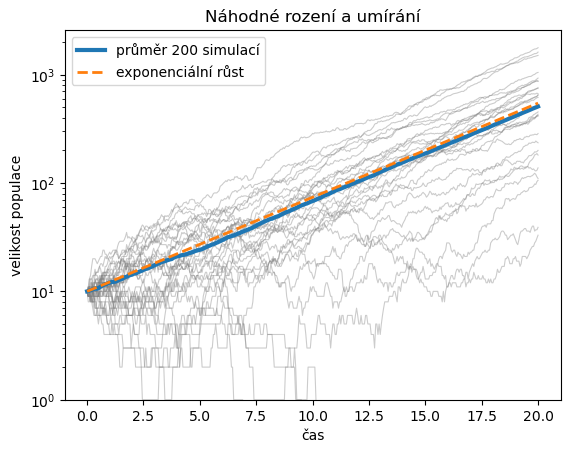

In [3]:
rng = np.random.default_rng(42) # generátor náhodných čísel

def rozeni_umirani(N0=10, b=1, d=0.8, T=20, dt=0.05):
    """
    Agentní model náhodného rození a umírání.
    Vrací velikosti populace v časových krocích.
    """
    kroky = int(T/dt)
    N = np.zeros(kroky+1, dtype=int)
    N[0] = N0
    for k in range(kroky):
        nahoda_rozeni = rng.random(N[k])  # jedno číslo pro každého jedince
        nahoda_umirani = rng.random(N[k])
        narozeni = np.sum(nahoda_rozeni < b*dt)
        uhynuli = np.sum(nahoda_umirani < d*dt)
        N[k+1] = N[k] + narozeni - uhynuli
    return N

T, dt, N0, b, d = 20, 0.05, 10, 1, 0.8
t = np.arange(0, T+dt/2, dt)
realizace = np.array([rozeni_umirani(N0=N0, b=b, d=d, T=T, dt=dt)
                      for i in range(200)])

fig, ax = plt.subplots()
for N in realizace[:30]:
    ax.plot(t, N, color="gray", alpha=0.4, lw=0.8)
ax.plot(t, realizace.mean(axis=0), lw=3, label="průměr 200 simulací")
ax.plot(t, N0*np.exp((b-d)*t), "--", lw=2, label="exponenciální růst")
ax.set(
    xlabel="čas",
    ylabel="velikost populace",
    title="Náhodné rození a umírání",
    yscale="log",
    ylim=(1, None))
ax.legend();

Šedé křivky jsou jednotlivé simulace. Průměr mnoha simulací kopíruje řešení
diferenciální rovnice exponenciálního růstu. Jednotlivé simulace se ale od sebe
liší a některé populace vymřely, přestože porodnost je větší než úmrtnost. To
deterministický model nedokáže popsat. (V grafu s logaritmickou osou jsou
vymřelé populace mimo zobrazovanou oblast.)

In [4]:
vymrele = np.sum(realizace[:, -1] == 0)
print(f"Vymřelo {vymrele} populací z {len(realizace)}.")

Vymřelo 22 populací z 200.


```{prf:remark} Pravděpodobnost vymření
Pro model náhodného rození a umírání se spojitým časem je možné odvodit, že
pokud $b>d$, populace s počáteční velikostí $N_0$ vymře s pravděpodobností
$$P=\left(\frac db\right)^{N_0}.$$
Pravděpodobnost vymření tedy rychle klesá s velikostí počáteční populace. Toto
je jeden z důvodů, proč jsou reintrodukce a záchranné programy úspěšnější, pokud
se vypouští větší počet jedinců najednou.
```

Ověříme tento vztah simulací. Pro různé počáteční velikosti populace spustíme
model mnohokrát a spočítáme, jaký podíl populací vymřel. Simulaci ukončíme,
jakmile populace vymře nebo naopak dosáhne velikosti 200 jedinců. Taková
populace už prakticky nemá šanci vymřít.

In [5]:
def vymre(N0, b=1, d=0.8, dt=0.05, N_max=200):
    """Vrací True, pokud populace vymře dříve, než dosáhne velikosti N_max."""
    N = N0
    while 0 < N < N_max:
        narozeni = np.sum(rng.random(N) < b*dt)
        uhynuli = np.sum(rng.random(N) < d*dt)
        N = N + narozeni - uhynuli
    return N == 0

opakovani = 400
pocatecni = [1, 2, 3, 5, 8]
vysledky = pd.DataFrame(
    {"simulace": [np.mean([vymre(N0) for i in range(opakovani)])
                  for N0 in pocatecni],
     "teorie (d/b)^N0": [(d/b)**N0 for N0 in pocatecni]},
    index=pocatecni)
vysledky.index.name = "N0"
vysledky.style.format(precision=3)

,simulace,teorie (d/b)^N0
N0,,
1,0.812,0.800
2,0.610,0.640
3,0.500,0.512
5,0.335,0.328
8,0.175,0.168


### Stejný model v knihovně Mesa

V knihovně Mesa popíšeme nejprve jedince. V každém kroku se s pravděpodobností
$b\,\Delta t$ rozmnoží a s pravděpodobností $d\,\Delta t$ uhyne. Parametry
modelu a aktuální úmrtnost si jedinec přečte z modelu. Úmrtnost nastavuje
model na začátku každého kroku v metodě `nastav_umrtnost`. Zatím je konstantní,
ale v dalším příkladu ji snadno změníme. Potomci narození v daném kroku se
v tomto kroku ještě nerozhodují, metoda `shuffle_do` prochází jen agenty
existující na začátku kroku.

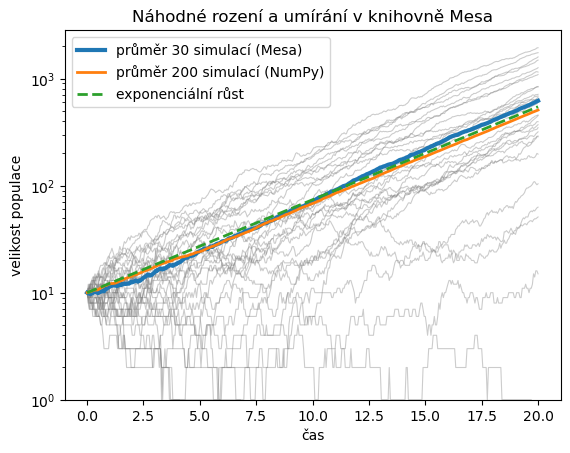

In [6]:
class Jedinec(mesa.Agent):
    """Jedinec, který se může rozmnožit nebo uhynout."""
    def step(self):
        m = self.model
        if self.random.random() < m.b*m.dt:
            Jedinec(m)          # narodí se potomek
        if self.random.random() < m.umrtnost*m.dt:
            self.remove()       # jedinec uhyne


class RozeniUmirani(mesa.Model):
    def __init__(self, N0=10, b=1, d=0.8, dt=0.05, seed=None):
        super().__init__(rng=seed)
        self.b, self.d, self.dt = b, d, dt
        Jedinec.create_agents(self, N0)      # počáteční populace
        self.datacollector = mesa.DataCollector(
            model_reporters={"N": lambda m: len(m.agents)})
        self.datacollector.collect(self)

    def nastav_umrtnost(self):
        self.umrtnost = self.d

    def step(self):
        self.nastav_umrtnost()
        self.agents.shuffle_do("step")
        self.datacollector.collect(self)


T, dt, N0, b, d = 20, 0.05, 10, 1, 0.8
t = np.arange(0, T+dt/2, dt)
realizace_mesa = []
for i in range(30):
    model = RozeniUmirani(N0=N0, b=b, d=d, dt=dt, seed=i)
    for k in range(int(T/dt)):
        model.step()
    realizace_mesa.append(model.datacollector.get_model_vars_dataframe()["N"])
realizace_mesa = np.array(realizace_mesa)

fig, ax = plt.subplots()
for N in realizace_mesa:
    ax.plot(t, N, color="gray", alpha=0.4, lw=0.8)
ax.plot(t, realizace_mesa.mean(axis=0), lw=3, label="průměr 30 simulací (Mesa)")
ax.plot(t, realizace.mean(axis=0), lw=2, label="průměr 200 simulací (NumPy)")
ax.plot(t, N0*np.exp((b-d)*t), "--", lw=2, label="exponenciální růst")
ax.set(
    xlabel="čas",
    ylabel="velikost populace",
    title="Náhodné rození a umírání v knihovně Mesa",
    yscale="log",
    ylim=(1, None))
ax.legend();

Také pravděpodobnost vymření dostaneme stejnou jako v předchozí variantě.

In [7]:
def vymre_mesa(N0, seed, N_max=100):
    model = RozeniUmirani(N0=N0, seed=seed)
    while 0 < len(model.agents) < N_max:
        model.step()
    return len(model.agents) == 0

pocatecni = [1, 3, 5]
vysledky_mesa = pd.DataFrame(
    {"simulace Mesa": [np.mean([vymre_mesa(N0, seed) for seed in range(200)])
                       for N0 in pocatecni],
     "teorie (d/b)^N0": [(d/b)**N0 for N0 in pocatecni]},
    index=pocatecni)
vysledky_mesa.index.name = "N0"
vysledky_mesa.style.format(precision=3)

,simulace Mesa,teorie (d/b)^N0
N0,,
1,0.775,0.800
3,0.520,0.512
5,0.340,0.328


## Logistický růst z pravidel pro jedince

```{index} single: Model ; logistického růstu agentní
```

Aby populace nerostla neomezeně, musí se v modelu projevit vnitrodruhová
konkurence. Předpokládejme, že porodnost je stále rovna $b$, ale úmrtnost roste
s velikostí populace, například proto, že se jedinci více dělí o potravu. Zvolme
úmrtnost jedince v populaci velikosti $N$ ve tvaru
$$d(N)=d_0+(b-d_0)\frac NK.$$
Očekávaná rychlost změny velikosti populace potom je
$$bN-d(N)N=(b-d_0)N-(b-d_0)\frac{N^2}{K}=rN\left(1-\frac NK\right),$$
kde $r=b-d_0$. Pro velké populace tedy očekáváme chování popsané
logistickou rovnicí, kterou známe z kapitoly o autonomních diferenciálních
rovnicích.

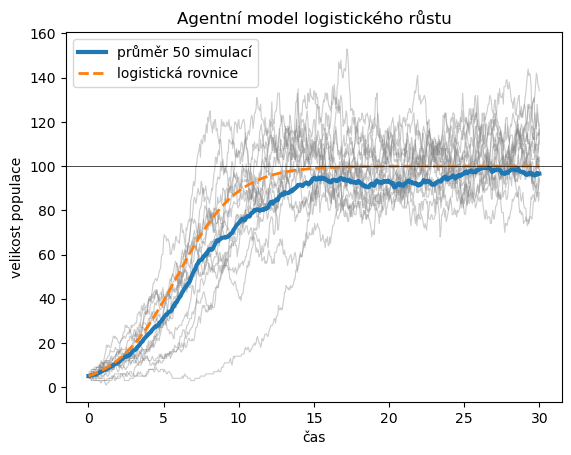

In [8]:
def logisticky_agenti(N0=5, b=1, d0=0.5, K=100, T=30, dt=0.05):
    kroky = int(T/dt)
    N = np.zeros(kroky+1, dtype=int)
    N[0] = N0
    for k in range(kroky):
        umrtnost = d0 + (b-d0)*N[k]/K   # úmrtnost závisí na hustotě
        narozeni = np.sum(rng.random(N[k]) < b*dt)
        uhynuli = np.sum(rng.random(N[k]) < umrtnost*dt)
        N[k+1] = N[k] + narozeni - uhynuli
    return N

N0, b, d0, K, T, dt = 5, 1, 0.5, 100, 30, 0.05
t = np.arange(0, T+dt/2, dt)
realizace = np.array([logisticky_agenti(N0, b, d0, K, T, dt) for i in range(50)])

r = b - d0
ode = solve_ivp(lambda t, N: r*N*(1-N/K), [0, T], [N0], t_eval=t)

fig, ax = plt.subplots()
for N in realizace[:15]:
    ax.plot(t, N, color="gray", alpha=0.4, lw=0.8)
ax.plot(t, realizace.mean(axis=0), lw=3, label="průměr 50 simulací")
ax.plot(ode.t, ode.y[0], "--", lw=2, label="logistická rovnice")
ax.axhline(K, color="k", lw=0.5)
ax.set(
    xlabel="čas",
    ylabel="velikost populace",
    title="Agentní model logistického růstu")
ax.legend();

Průměr simulací leží o něco níže než řešení logistické rovnice. Některé
populace na začátku náhodou vymřou a navíc úmrtnost závisí na druhé mocnině
velikosti populace, takže kolísání velikosti populace v průměru zvyšuje
úmrtnost. Jednotlivé populace v agentním modelu navíc nedosáhnou nosné kapacity
a nezůstanou v ní, jako je tomu u řešení logistické rovnice. Velikost populace kolem nosné kapacity
neustále náhodně kolísá. Rozdělení velikostí populace v pozdějších časech
ukazuje následující histogram.

Průměr 94.6, směrodatná odchylka 24.2


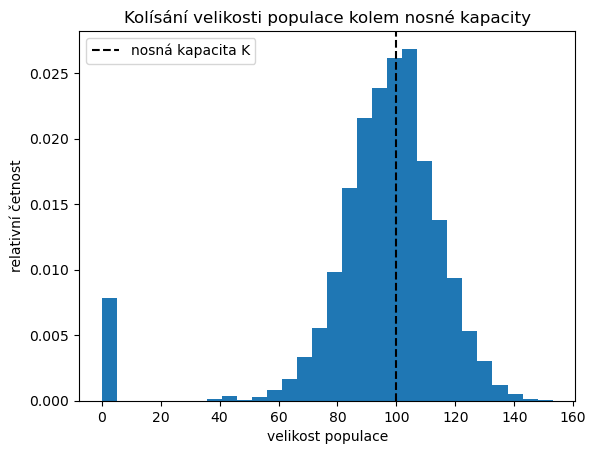

In [9]:
ustalene = realizace[:, t > 15].flatten()

fig, ax = plt.subplots()
ax.hist(ustalene, bins=30, density=True)
ax.axvline(K, color="k", ls="--", label="nosná kapacita K")
ax.set(
    xlabel="velikost populace",
    ylabel="relativní četnost",
    title="Kolísání velikosti populace kolem nosné kapacity")
ax.legend()
print(f"Průměr {ustalene.mean():.1f}, směrodatná odchylka {ustalene.std():.1f}")

Pro populace s malou nosnou kapacitou prostředí je kolísání velikosti populace
relativně velké. Dříve či později nastane situace, kdy náhodně uhyne více
jedinců, než se narodí, a populace vymře, přestože deterministický model
předpovídá stabilní rovnováhu v bodě $N=K$. Tento jev je jedním z
argumentů pro koncept *minimální životaschopné populace*, který se používá v
ochraně přírody.

```{index} Minimální životaschopná populace
```

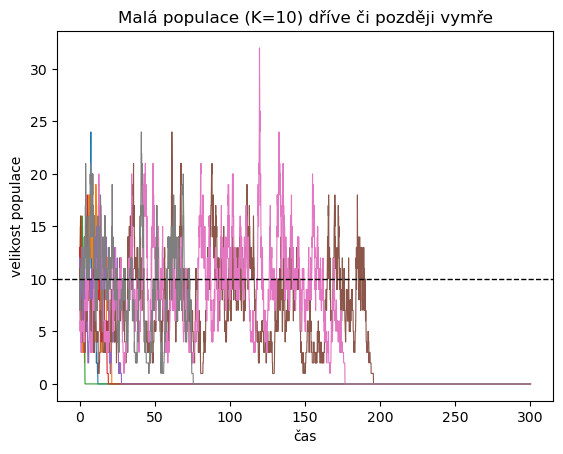

In [10]:
T_dlouhe = 300
t = np.arange(0, T_dlouhe+dt/2, dt)
fig, ax = plt.subplots()
for i in range(8):
    N = logisticky_agenti(N0=10, K=10, T=T_dlouhe)
    ax.plot(t, N, lw=0.8)
ax.axhline(10, color="k", ls="--", lw=1)
ax.set(
    xlabel="čas",
    ylabel="velikost populace",
    title="Malá populace (K=10) dříve či později vymře");

### Stejný model v knihovně Mesa

Zde se ukáže výhoda objektového přístupu. Jedince ani model není nutné psát
znovu. Vytvoříme potomka třídy `RozeniUmirani`, který změní pouze způsob
výpočtu úmrtnosti. Ta se nyní počítá z aktuálního počtu agentů
`len(self.agents)`. Vše ostatní (rozmnožování, umírání, sběr dat) zůstává stejné.

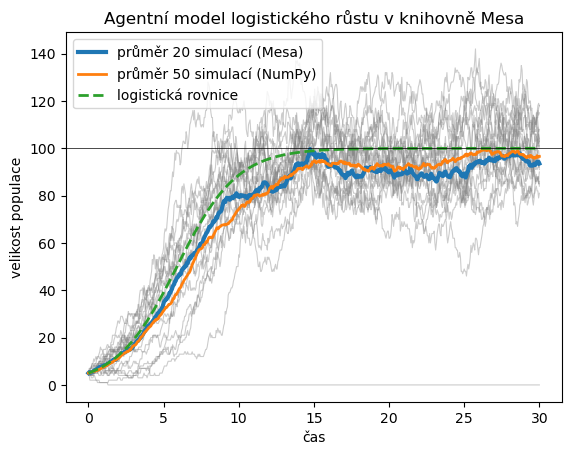

In [11]:
class Logisticky(RozeniUmirani):
    def __init__(self, N0=5, b=1, d0=0.5, K=100, dt=0.05, seed=None):
        self.K = K
        super().__init__(N0=N0, b=b, d=d0, dt=dt, seed=seed)

    def nastav_umrtnost(self):
        # úmrtnost závisí na velikosti populace
        self.umrtnost = self.d + (self.b - self.d)*len(self.agents)/self.K


N0, b, d0, K, T, dt = 5, 1, 0.5, 100, 30, 0.05
t = np.arange(0, T+dt/2, dt)
realizace_mesa = []
for i in range(20):
    model = Logisticky(N0=N0, b=b, d0=d0, K=K, dt=dt, seed=i)
    for k in range(int(T/dt)):
        model.step()
    realizace_mesa.append(model.datacollector.get_model_vars_dataframe()["N"])
realizace_mesa = np.array(realizace_mesa)

fig, ax = plt.subplots()
for N in realizace_mesa:
    ax.plot(t, N, color="gray", alpha=0.4, lw=0.8)
ax.plot(t, realizace_mesa.mean(axis=0), lw=3, label="průměr 20 simulací (Mesa)")
ax.plot(t, realizace.mean(axis=0), lw=2, label="průměr 50 simulací (NumPy)")
ax.plot(ode.t, ode.y[0], "--", lw=2, label="logistická rovnice")
ax.axhline(K, color="k", lw=0.5)
ax.set(
    xlabel="čas",
    ylabel="velikost populace",
    title="Agentní model logistického růstu v knihovně Mesa")
ax.legend();

## Prostorový model dravce a kořisti

```{index} single: Model ; dravce a kořisti agentní
```

```{margin} Software pro agentní modely
Agentní modely je možné programovat v libovolném jazyce. Často se používá
prostředí [NetLogo](https://ccl.northwestern.edu/netlogo/), které je určeno
právě pro agentní modely a obsahuje knihovnu hotových modelů (včetně modelu
vlků a ovcí). V Pythonu je k dispozici knihovna
[Mesa](https://mesa.readthedocs.io/), kterou v této kapitole používáme vedle
knihovny NumPy. Mesa obsahuje i nástroje pro interaktivní vizualizaci modelu
v prohlížeči a pro hromadné spouštění simulací s různými parametry.
```

Jednou ze silných stránek agentních modelů je možnost zahrnout do modelu prostor.
V Lotkově–Volterrově modelu předpokládáme, že se každý dravec může setkat s
každým jedincem kořisti a že počet setkání je úměrný součinu velikostí obou
populací. Ve skutečnosti se ale dravec setká jenom s kořistí ve svém okolí.

Uvažujme čtvercové území rozdělené na $L\times L$ políček. Abychom se vyhnuli
problémům na okraji, budeme předpokládat, že agent, který opustí území na jedné
straně, se objeví na protější straně (takzvané periodické okrajové podmínky).
Na území žijí jedinci kořisti a dravci. V každém časovém kroku platí následující
pravidla.

* **Pohyb:** Každý agent se přesune na náhodně zvolené sousední políčko (nebo
  zůstane na místě).
* **Rozmnožování kořisti:** Každý jedinec kořisti se s pravděpodobností
  $p$ rozmnoží, pokud je na jeho políčku méně než daný počet jedinců kořisti
  (lokální nosná kapacita, potravní zdroje políčka jsou omezené). Potomek zůstává
  na stejném políčku.
* **Energie dravce:** Každý dravec spotřebuje v každém kroku jednu jednotku
  energie.
* **Lov:** Pokud je na políčku s dravcem nějaká kořist, dravec jednoho jedince
  uloví a získá tím zadaný počet jednotek energie.
* **Rozmnožování dravce:** Dravec, jehož energie dosáhne zadané hranice, se
  rozmnoží a rozdělí svou energii rovným dílem mezi sebe a potomka.
* **Smrt dravce:** Dravec, kterému dojde energie, uhyne.

Stav každého agenta je dán jeho souřadnicemi a u dravce navíc zásobou energie.
Souřadnice všech jedinců kořisti uchováváme v polích `kx`, `ky`, souřadnice
dravců v polích `dx`, `dy` a energii dravců v poli `energie`.

In [12]:
def dravec_korist(
    L=40,            # velikost území L x L
    n_korist=400,    # počáteční počet kořisti
    n_dravec=60,     # počáteční počet dravců
    kroky=800,       # délka simulace
    p_mnozeni=0.2,   # pravděpodobnost rozmnožení kořisti
    kapacita=3,      # maximální počet kořisti na políčku pro rozmnožení
    zisk=2,          # energie získaná ulovením kořisti
    prah=8,          # energie potřebná k rozmnožení dravce
    seed=1,
    snimky=()        # časy, ve kterých si uložíme rozmístění agentů
    ):
    rng = np.random.default_rng(seed)
    kx = rng.integers(0, L, n_korist)
    ky = rng.integers(0, L, n_korist)
    dx = rng.integers(0, L, n_dravec)
    dy = rng.integers(0, L, n_dravec)
    energie = rng.integers(1, prah, n_dravec).astype(float)
    historie = []
    ulozene_snimky = {}

    for krok in range(kroky):
        # pohyb všech agentů o jedno políčko
        kx = (kx + rng.integers(-1, 2, kx.size)) % L
        ky = (ky + rng.integers(-1, 2, ky.size)) % L
        dx = (dx + rng.integers(-1, 2, dx.size)) % L
        dy = (dy + rng.integers(-1, 2, dy.size)) % L

        # rozmnožování kořisti s lokální nosnou kapacitou
        policko = kx*L + ky
        pocet_na_policku = np.bincount(policko, minlength=L*L)
        mnozi = ((rng.random(kx.size) < p_mnozeni)
                 & (pocet_na_policku[policko] < kapacita))
        kx = np.concatenate([kx, kx[mnozi]])
        ky = np.concatenate([ky, ky[mnozi]])

        # lov: pro každé políčko seznam jedinců kořisti, kteří na něm jsou
        korist_na_policku = defaultdict(list)
        for i, p in enumerate(kx*L + ky):
            korist_na_policku[p].append(i)
        ziva = np.ones(kx.size, dtype=bool)
        energie = energie - 1
        for j in rng.permutation(dx.size):   # dravci loví v náhodném pořadí
            seznam = korist_na_policku.get(dx[j]*L + dy[j])
            if seznam:
                ziva[seznam.pop()] = False
                energie[j] += zisk
        kx, ky = kx[ziva], ky[ziva]

        # rozmnožování a smrt dravců
        rodi = energie >= prah
        energie[rodi] = energie[rodi]/2
        dx = np.concatenate([dx, dx[rodi]])
        dy = np.concatenate([dy, dy[rodi]])
        energie = np.concatenate([energie, energie[rodi]])
        zije = energie > 0
        dx, dy, energie = dx[zije], dy[zije], energie[zije]

        historie.append([kx.size, dx.size])
        if krok in snimky:
            ulozene_snimky[krok] = (kx.copy(), ky.copy(), dx.copy(), dy.copy())

    historie = pd.DataFrame(historie, columns=["kořist", "dravec"])
    return historie, ulozene_snimky

casy_snimku = (420, 435, 450, 465)
start = time.perf_counter()
historie, snimky = dravec_korist(snimky=casy_snimku)
cas_numpy = time.perf_counter() - start
print(f"Doba výpočtu (NumPy): {cas_numpy:.1f} s")
historie.iloc[::100]

Doba výpočtu (NumPy): 0.5 s


,kořist,dravec
0,454,58
100,3064,716
200,4306,174
300,1691,58
400,533,347
500,3590,526
600,3369,124
700,1285,191


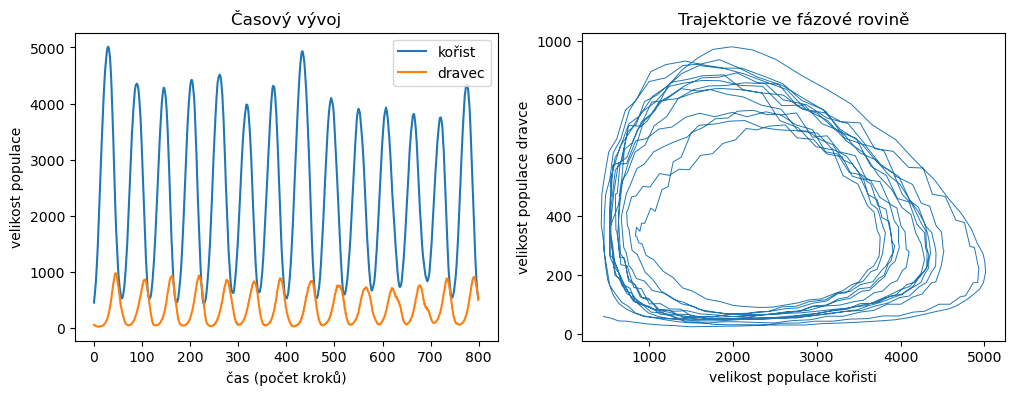

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
historie.plot(ax=axs[0])
axs[0].set(
    xlabel="čas (počet kroků)",
    ylabel="velikost populace",
    title="Časový vývoj")

axs[1].plot(historie["kořist"], historie["dravec"], lw=0.7)
axs[1].set(
    xlabel="velikost populace kořisti",
    ylabel="velikost populace dravce",
    title="Trajektorie ve fázové rovině");

Podobně jako v Lotkově–Volterrově modelu populace oscilují a maximum populace
dravce následuje se zpožděním za maximem populace kořisti. Na rozdíl od
deterministického modelu však amplituda i perioda oscilací náhodně kolísají a
trajektorie ve fázové rovině není uzavřená křivka.

Rozmístění agentů v území během jednoho cyklu ukazují následující snímky.
Rozmístění agentů není rovnoměrné. Dravci se soustředí tam, kde je dostatek
kořisti, a vylovená místa zůstávají prázdná. V místech, kde dravci kořist
vylovili, dravci hynou hlady a tato místa později znovu osídlí kořist z okolí.
Prostorová struktura tak přispívá k dlouhodobému soužití obou druhů.

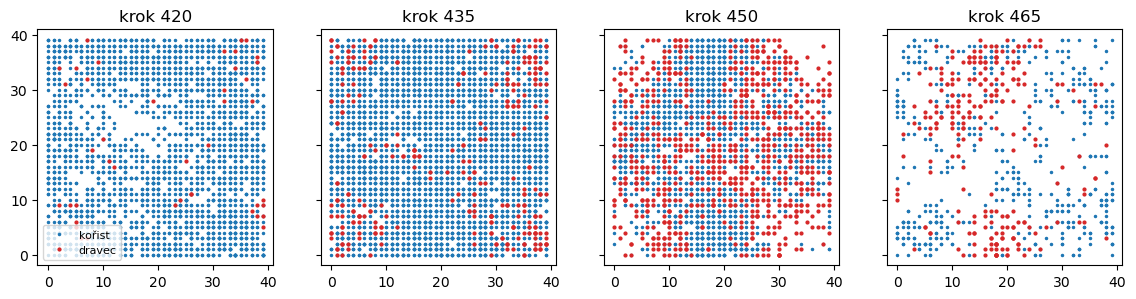

In [14]:
fig, axs = plt.subplots(1, len(casy_snimku), figsize=(14, 3.8),
                        sharex=True, sharey=True)
for ax, cas in zip(axs, casy_snimku):
    kx, ky, dx, dy = snimky[cas]
    ax.plot(kx, ky, ".", ms=3, color="C0", label="kořist")
    ax.plot(dx, dy, ".", ms=4, color="C3", label="dravec")
    ax.set(title=f"krok {cas}", aspect="equal")
axs[0].legend(loc="lower left", fontsize=8);

```{prf:remark} Význam prostoru pro soužití dravce a kořisti
Pokud bychom agenty v každém kroku náhodně rozmístili po celém území (dobře
promíchaná populace), dravec by se nejprve přemnožil, vylovil kořist a během
několika desítek kroků vymřel. Podobně dopadne simulace se stejnými pravidly na
příliš malém území (například $L=15$). Prostorová heterogenita, kdy se lokální
populace v různých částech území nacházejí v různých fázích cyklu, stabilizuje
celé společenstvo. Vyzkoušejte si to změnou parametru `L` nebo úpravou pravidla
pro pohyb. Na podobném principu
funguje přežívání metapopulací.
```

### Stejný model v knihovně Mesa

V knihovně Mesa odpovídá každé pravidlo jedné metodě agenta. Kořist i dravec
jsou odvozeni od třídy `CellAgent`, takže znají své políčko `self.cell`.
Příkaz `self.cell.get_neighborhood(include_center=True).select_random_cell()`
vybere náhodné políčko z okolí (včetně současného). Seznam agentů na políčku
je `self.cell.agents`. Mřížka `OrthogonalMooreGrid` s parametrem `torus=True`
má periodické okrajové podmínky. Metoda `step` modelu určuje pořadí
pravidel v jednom časovém kroku a je stejné jako ve verzi v NumPy.

Jediný drobný rozdíl je v rozmnožování kořisti. V NumPy se všichni jedinci
rozhodují podle počtu kořisti na políčku na začátku kroku. V Mesa jedinci
přicházejí na řadu postupně a vidí i potomky, kteří se na políčku narodili
před nimi. Na chování modelu to nemá podstatný vliv.

Doba výpočtu (Mesa): 4.8 s


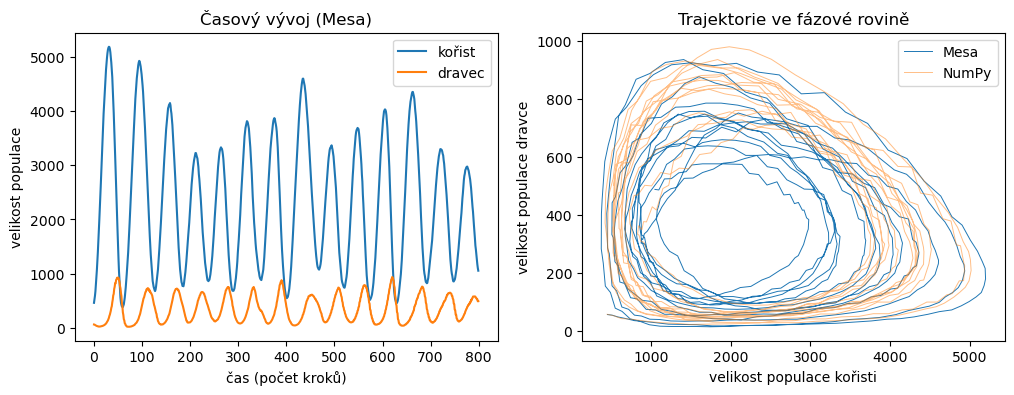

In [15]:
class Korist(CellAgent):
    def __init__(self, model, cell):
        super().__init__(model)
        self.cell = cell

    def pohyb(self):
        self.cell = self.cell.get_neighborhood(include_center=True).select_random_cell()

    def mnozeni(self):
        pocet = sum(isinstance(a, Korist) for a in self.cell.agents)
        if pocet < self.model.kapacita and self.random.random() < self.model.p_mnozeni:
            Korist(self.model, self.cell)        # potomek na stejném políčku


class Dravec(CellAgent):
    def __init__(self, model, cell, energie):
        super().__init__(model)
        self.cell = cell
        self.energie = energie

    def pohyb(self):
        self.cell = self.cell.get_neighborhood(include_center=True).select_random_cell()

    def lov(self):
        self.energie -= 1
        korist = [a for a in self.cell.agents if isinstance(a, Korist)]
        if korist:
            korist[-1].remove()                   # ulovená kořist zmizí
            self.energie += self.model.zisk

    def mnozeni_a_smrt(self):
        if self.energie >= self.model.prah:
            self.energie = self.energie/2
            Dravec(self.model, self.cell, self.energie)
        if self.energie <= 0:
            self.remove()


class DravecKorist(mesa.Model):
    def __init__(self, L=40, n_korist=400, n_dravec=60, p_mnozeni=0.2,
                 kapacita=3, zisk=2, prah=8, seed=1):
        super().__init__(rng=seed)
        self.p_mnozeni = p_mnozeni
        self.kapacita = kapacita
        self.zisk = zisk
        self.prah = prah
        self.grid = OrthogonalMooreGrid((L, L), torus=True, random=self.random)
        policka = self.grid.all_cells.cells
        for i in range(n_korist):
            Korist(self, self.random.choice(policka))
        for i in range(n_dravec):
            Dravec(self, self.random.choice(policka), self.random.randint(1, prah-1))
        self.datacollector = mesa.DataCollector(model_reporters={
            "kořist": lambda m: len(m.agents_by_type[Korist]),
            "dravec": lambda m: len(m.agents_by_type[Dravec])})

    def step(self):
        self.agents.shuffle_do("pohyb")
        self.agents_by_type[Korist].shuffle_do("mnozeni")
        self.agents_by_type[Dravec].shuffle_do("lov")
        self.agents_by_type[Dravec].shuffle_do("mnozeni_a_smrt")
        self.datacollector.collect(self)


start = time.perf_counter()
model = DravecKorist()
for krok in range(800):
    model.step()
cas_mesa = time.perf_counter() - start
print(f"Doba výpočtu (Mesa): {cas_mesa:.1f} s")
historie_mesa = model.datacollector.get_model_vars_dataframe()

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
historie_mesa.plot(ax=axs[0])
axs[0].set(
    xlabel="čas (počet kroků)",
    ylabel="velikost populace",
    title="Časový vývoj (Mesa)")
axs[1].plot(historie_mesa["kořist"], historie_mesa["dravec"], lw=0.7, label="Mesa")
axs[1].plot(historie["kořist"], historie["dravec"], lw=0.7, alpha=0.5, label="NumPy")
axs[1].set(
    xlabel="velikost populace kořisti",
    ylabel="velikost populace dravce",
    title="Trajektorie ve fázové rovině")
axs[1].legend();

Obě implementace dávají kvalitativně stejný výsledek. Konkrétní průběh se liší,
protože každá verze používá jinou posloupnost náhodných čísel. Rozmístění
agentů na konci simulace získáme přímo z políček, na kterých agenti stojí.

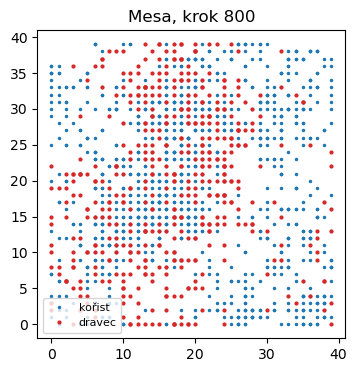

In [16]:
fig, ax = plt.subplots(figsize=(4, 4))
for druh, barva, velikost, popis in [(Korist, "C0", 3, "kořist"),
                                     (Dravec, "C3", 4, "dravec")]:
    souradnice = np.array([a.cell.coordinate for a in model.agents_by_type[druh]])
    if len(souradnice) > 0:
        ax.plot(*souradnice.T, ".", ms=velikost, color=barva, label=popis)
ax.set(title=f"Mesa, krok {len(historie_mesa)}", aspect="equal")
ax.legend(loc="lower left", fontsize=8);

## Konkurence dvou druhů

```{index} single: Model ; konkurence agentní
```

V posledním příkladu se vrátíme k modelu konkurence dvou druhů z kapitoly o
modelech konkurence populací a sestavíme jej z pravidel pro jedince. Tento model
naprogramujeme pouze v knihovně Mesa. Navážeme na agentní model logistického
růstu. V prostředí žijí jedinci dvou druhů $x$ a $y$, kteří se
rozmnožují s porodností $b$. Úmrtnost jedince roste s počtem jedinců vlastního
druhu (vnitrodruhová konkurence) i s počtem jedinců druhého druhu (mezidruhová
konkurence). Je-li v populaci $x$ jedinců prvního a $y$ jedinců druhého druhu,
je úmrtnost
$$
\begin{aligned}
d_x&=d_0+(b-d_0)\frac{x+c_{xy}\,y}{K},\\
d_y&=d_0+(b-d_0)\frac{y+c_{yx}\,x}{K}.
\end{aligned}
$$
Koeficient $c_{xy}$ udává, kolika jedincům druhu $x$ odpovídá z hlediska
konkurence jeden jedinec druhu $y$. Podobně koeficient $c_{yx}$ udává vliv druhu
$x$ na druh $y$. Stejným výpočtem jako u logistického růstu dostaneme, že se
pro velké populace dá očekávat chování popsané soustavou
$$
\begin{aligned}
\frac{\mathrm dx}{\mathrm dt}&=rx\left(1-\frac{x+c_{xy}\,y}{K}\right),\\
\frac{\mathrm dy}{\mathrm dt}&=ry\left(1-\frac{y+c_{yx}\,x}{K}\right),
\end{aligned}
$$
kde $r=b-d_0$. Jedná se o model konkurence z kapitoly o modelech konkurence
populací s parametry $a=\alpha=r$, $b=\beta=\frac rK$, $c=\frac{r c_{xy}}K$ a
$\gamma=\frac{r c_{yx}}K$. Nulklina $x+c_{xy}y=K$ prochází body $[K,0]$ a
$\left[0,\frac K{c_{xy}}\right]$, nulklina $y+c_{yx}x=K$ body
$\left[\frac K{c_{yx}},0\right]$ a $[0,K]$. Podle velikosti koeficientů
konkurence tedy nastane

* *dominance druhu $x$* pro $c_{xy}<1<c_{yx}$, kdy druh $y$ vymře,
* *slabá konkurence* pro $c_{xy}<1$ a $c_{yx}<1$, kdy oba druhy koexistují,
* *silná konkurence* pro $c_{xy}>1$ a $c_{yx}>1$, kdy přežije jeden z druhů
  podle počátečních podmínek.

Agent `JedinecDruhu` se chová stejně jako agent `Jedinec` z modelu náhodného
rození a umírání. Navíc má atribut `druh`, který zdědí i jeho potomek, a
úmrtnost si přečte ze slovníku `umrtnost` podle svého druhu. Model na začátku
každého kroku spočítá jedince obou druhů a nastaví jejich úmrtnost.

In [17]:
class JedinecDruhu(mesa.Agent):
    """Jedinec jednoho ze dvou konkurujících si druhů."""
    def __init__(self, model, druh):
        super().__init__(model)
        self.druh = druh

    def step(self):
        m = self.model
        if self.random.random() < m.b*m.dt:
            JedinecDruhu(m, self.druh)            # potomek stejného druhu
        if self.random.random() < m.umrtnost[self.druh]*m.dt:
            self.remove()


class Konkurence(mesa.Model):
    def __init__(self, x0=10, y0=10, c_xy=0.5, c_yx=0.5, K=100, b=1, d0=0.5,
                 dt=0.05, seed=None):
        super().__init__(rng=seed)
        self.c_xy, self.c_yx, self.K = c_xy, c_yx, K
        self.b, self.d0, self.dt = b, d0, dt
        for i in range(x0):
            JedinecDruhu(self, "x")
        for i in range(y0):
            JedinecDruhu(self, "y")
        self.datacollector = mesa.DataCollector(model_reporters={
            "x": lambda m: m.pocet("x"),
            "y": lambda m: m.pocet("y")})
        self.datacollector.collect(self)

    def pocet(self, druh):
        return sum(a.druh == druh for a in self.agents)

    def step(self):
        x, y = self.pocet("x"), self.pocet("y")
        s = (self.b - self.d0)/self.K
        self.umrtnost = {"x": self.d0 + s*(x + self.c_xy*y),
                         "y": self.d0 + s*(y + self.c_yx*x)}
        self.agents.shuffle_do("step")
        self.datacollector.collect(self)


def simuluj(c_xy, c_yx, x0=10, y0=10, T=60, dt=0.05, seed=None):
    model = Konkurence(x0=x0, y0=y0, c_xy=c_xy, c_yx=c_yx, dt=dt, seed=seed)
    for k in range(int(T/dt)):
        model.step()
    return model.datacollector.get_model_vars_dataframe()

Pro každou ze tří variant spustíme několik simulací se stejnou počáteční
podmínkou $x_0=y_0=10$ a porovnáme je s řešením soustavy diferenciálních rovnic.

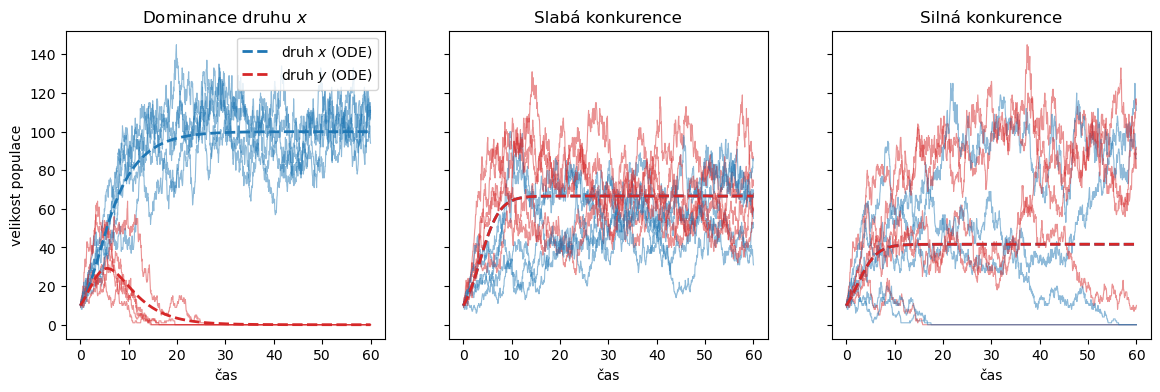

In [18]:
varianty = {
    "Dominance druhu $x$": (0.6, 1.4),
    "Slabá konkurence": (0.5, 0.5),
    "Silná konkurence": (1.4, 1.4),
}
K, r, T, dt, x0, y0 = 100, 0.5, 60, 0.05, 10, 10
t = np.arange(0, T+dt/2, dt)
simulace = {nazev: [simuluj(c_xy, c_yx, x0, y0, T, dt, seed=i) for i in range(5)]
            for nazev, (c_xy, c_yx) in varianty.items()}

fig, axs = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (nazev, (c_xy, c_yx)) in zip(axs, varianty.items()):
    for df in simulace[nazev]:
        ax.plot(t, df["x"], color="C0", alpha=0.5, lw=0.8)
        ax.plot(t, df["y"], color="C3", alpha=0.5, lw=0.8)
    ode = solve_ivp(lambda t, X: [r*X[0]*(1-(X[0]+c_xy*X[1])/K),
                                  r*X[1]*(1-(X[1]+c_yx*X[0])/K)],
                    [0, T], [x0, y0], t_eval=t)
    ax.plot(ode.t, ode.y[0], "--", color="C0", lw=2, label="druh $x$ (ODE)")
    ax.plot(ode.t, ode.y[1], "--", color="C3", lw=2, label="druh $y$ (ODE)")
    ax.set(title=nazev, xlabel="čas")
axs[0].set(ylabel="velikost populace")
axs[0].legend();

Stejné simulace zobrazíme ve fázové rovině spolu s nulklinami. Zelená je
nulklina $x+c_{xy}y=K$, červená nulklina $y+c_{yx}x=K$. Čárkovaně je řešení
soustavy diferenciálních rovnic.

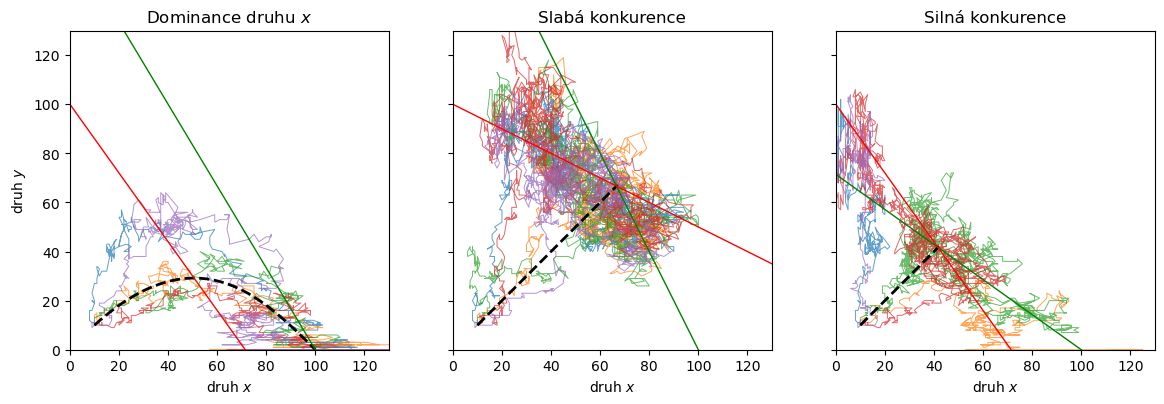

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True, sharey=True)
for ax, (nazev, (c_xy, c_yx)) in zip(axs, varianty.items()):
    for df in simulace[nazev]:
        ax.plot(df["x"], df["y"], lw=0.7, alpha=0.7)
    ode = solve_ivp(lambda t, X: [r*X[0]*(1-(X[0]+c_xy*X[1])/K),
                                  r*X[1]*(1-(X[1]+c_yx*X[0])/K)],
                    [0, T], [x0, y0], t_eval=t)
    ax.plot(ode.y[0], ode.y[1], "k--", lw=2)
    ax.plot([K, 0], [0, K/c_xy], color="g", lw=1)
    ax.plot([K/c_yx, 0], [0, K], color="r", lw=1)
    ax.set(title=nazev, xlabel="druh $x$", xlim=(0, 130), ylim=(0, 130),
           aspect="equal")
axs[0].set(ylabel="druh $y$");

Při dominanci druhu $x$ se agentní model chová stejně jako deterministický.
Druh $y$ nejprve roste, ale potom je vytlačen a vymře. Při slabé
konkurenci oba druhy koexistují a velikosti populací náhodně kolísají kolem
stabilního stacionárního bodu $x=y=\frac{K}{1+c}\approx 67$. Podobně jako u
logistického růstu ale platí, že v konečné populaci jeden z druhů dříve či
později náhodou vymře, jen to může trvat velmi dlouho.

Nejzajímavější je silná konkurence. Pro symetrickou počáteční podmínku $x_0=y_0$
se řešení soustavy diferenciálních rovnic pohybuje po přímce $y=x$ a dospěje do
sedla ve středu fázové roviny. Tam zůstane, protože žádný druh nemá výhodu.
V agentním modelu se ale velikosti populací náhodně odchýlí od rovnováhy a systém
dospěje do jednoho ze stabilních uzlů na osách. Který druh zvítězí, rozhoduje
náhoda. Ověříme to opakovanými simulacemi, které ukončíme, jakmile jeden z
druhů vymře.

In [20]:
def vitez(c_xy, c_yx, x0, y0, seed):
    model = Konkurence(x0=x0, y0=y0, c_xy=c_xy, c_yx=c_yx, seed=seed)
    while model.pocet("x") > 0 and model.pocet("y") > 0:
        model.step()
    return "x" if model.pocet("x") > 0 else "y"

pocatecni = [(40, 40), (45, 35), (50, 30)]
vysledky = pd.DataFrame(
    [pd.Series([vitez(1.4, 1.4, x0, y0, seed) for seed in range(50)]
               ).value_counts(normalize=True)
     for x0, y0 in pocatecni],
    index=[f"x0={x0}, y0={y0}" for x0, y0 in pocatecni]
    ).reindex(columns=["x", "y"]).fillna(0)
vysledky.columns = ["vítězí druh x", "vítězí druh y"]
vysledky.style.format(precision=2)

,vítězí druh x,vítězí druh y
"x0=40, y0=40",0.50,0.50
"x0=45, y0=35",0.64,0.36
"x0=50, y0=30",0.78,0.22


Při symetrické počáteční podmínce zvítězí každý z druhů přibližně v polovině
případů. Čím větší je počáteční náskok druhu $x$, tím častěji zvítězí. Na
rozdíl od deterministického modelu, kde o výsledku rozhoduje to, na které straně
separatrix sedla leží počáteční podmínka, je v agentním modelu výsledek dán
pravděpodobností. Blízko separatrix je tato pravděpodobnost blízká jedné
polovině.

## Shrnutí

Agentní modely popisují populaci zdola, prostřednictvím pravidel pro jedince.

* Pro velké a dobře promíchané populace se jejich průměrné chování shoduje s
  modely založenými na diferenciálních rovnicích (exponenciální a logistický
  růst, konkurence dvou druhů).
* Umožňují zachytit náhodné jevy, jako je vymření malé populace nebo kolísání
  kolem nosné kapacity, které deterministické modely nepostihnou. U silné
  konkurence dvou druhů rozhoduje o vítězi náhoda.
* Umožňují snadno zahrnout prostor, individuální rozdíly mezi jedinci a lokální
  interakce. Jak jsme viděli u modelu dravce a kořisti, prostorová struktura
  může zásadně změnit chování celého společenstva.
* Výsledky je nutné zpracovávat statisticky z mnoha opakování simulace a modely
  je obtížné analyzovat matematickými prostředky.

Srovnání obou způsobů programování ukazuje typický kompromis. Verze v NumPy
je rychlejší, ale pravidla pro jedince jsou v ní skryta v operacích s poli.
Verze v knihovně Mesa je pomalejší, ale její kód přímo odpovídá slovnímu popisu
modelu: každé pravidlo je jedna metoda agenta. Model se proto snadno čte,
kontroluje i rozšiřuje. Další druh, další vlastnost jedince nebo nové pravidlo
znamená přidat třídu, atribut nebo metodu. U modelu logistického růstu jsme
například využili celý model rození a umírání a změnili jen výpočet úmrtnosti.
Pro rychlé statistické experimenty s jednoduchými pravidly je vhodnější NumPy,
pro modely s mnoha druhy a složitým chováním jedinců knihovna Mesa.

Protože agentní modely mohou obsahovat mnoho pravidel a parametrů, je důležité
je pečlivě a srozumitelně popsat, aby je bylo možné zopakovat a zkontrolovat. K
tomu se v ekologii používá standardizovaný popis zvaný *protokol ODD* (Overview,
Design concepts, Details), viz {cite}`railsback`.

## Poznámka

Velká část této kapitoly byla připravena pomocí LLM Claude na základě předchozích kapitol. 

```{index} Protokol ODD
```